# TP — Montrer clairement le RNN comme modèle de langage

## Intitulé
**Implémentation d'un modèle de langage caractère par caractère avec un RNN from scratch**

## Objectif général
Ce TP reprend le notebook `RNN_FromScratch.ipynb` et le transforme en parcours pédagogique
progressif pour montrer clairement qu'un **RNN** peut servir de **modèle de langage**.

## Ce que l'étudiant doit comprendre
- pourquoi un RNN est adapté aux séquences ;
- comment l'état caché transporte l'information du passé ;
- comment passer d'un RNN simple à un **modèle de langage auto-régressif** ;
- comment encoder les caractères avec le **one-hot** ;
- comment entraîner le modèle avec une **entropie croisée** ;
- pourquoi le **gradient clipping** est important ;
- comment générer du texte à partir d'un préfixe.

## Prérequis
- Python
- PyTorch
- notions de tenseurs, couches, fonctions de perte
- notions de base sur les séquences

## Consigne pédagogique
Dans chaque partie :
1. lire l'explication,
2. exécuter le code,
3. répondre aux questions,
4. noter les dimensions importantes.

# Partie 1 — Pourquoi un RNN peut-il être un modèle de langage ?

Un **modèle de langage** cherche à modéliser une probabilité du type :

$$
P(x_1, x_2, \dots, x_T)=\prod_{t=1}^{T} P(x_t \mid x_1,\dots,x_{t-1})
$$

Dans un cadre caractère par caractère, cela signifie :

- lire une suite de caractères ;
- construire une mémoire du contexte ;
- prédire le caractère suivant.

Un **MLP classique** traite chaque entrée comme un vecteur isolé.
Un **RNN** réutilise un **état caché** \(h_t\) qui résume le passé.

## Question 1
Pourquoi un modèle sans mémoire est-il mal adapté à la prédiction du prochain caractère dans une séquence ?

In [27]:
# Installation éventuelle (à activer seulement si nécessaire)
# !pip -q install -U pip setuptools wheel
# !pip -q install d2l

In [28]:
!pip -q install -U pip setuptools wheel
!pip -q install numpy matplotlib pandas requests
!pip -q install d2l==1.0.3 --no-deps



[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: To modify pip, please run the following command:
C:\Users\Asus\AppData\Local\Programs\Python\Python312\python.exe -m pip -q install -U pip setuptools wheel

[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
import d2l, numpy as np
print("numpy:", np.__version__)


numpy: 2.4.0


In [30]:
%matplotlib inline
import torch
import torch.nn as nn
import torch.nn.functional as F # Added import for F
from d2l import torch as d2l

In [31]:
import torch
from torch import nn
from torch.nn import functional as F
import numpy as np
from d2l import torch as d2l

print("torch :", torch.__version__)
print("numpy :", np.__version__)


torch : 2.11.0+cpu
numpy : 2.4.0


# Partie 2 — Le coeur récurrent from scratch

Le coeur du RNN met à jour un état caché selon :

$$
h_t = \tanh(x_t W_{xh} + h_{t-1} W_{hh} + b_h)
$$

## Interprétation
- $x_t$ : information courante ;
- $h_{t-1}$ : mémoire du passé ;
- $h_t$ : nouveau résumé du contexte.

## Question 2
Quel est le rôle de $W_{xh}$, $W_{hh}$ et $b_h$ ?

In [32]:
class RNNScratch(d2l.Module):
    """RNN simple implémenté à partir de zéro."""

    def __init__(self, num_inputs, num_hiddens, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.W_xh = nn.Parameter(torch.randn(num_inputs, num_hiddens) * sigma)
        self.W_hh = nn.Parameter(torch.randn(num_hiddens, num_hiddens) * sigma)
        self.b_h = nn.Parameter(torch.zeros(num_hiddens))

## Lecture du code
- `num_inputs` : dimension de l'entrée ;
- `num_hiddens` : taille de l'état caché ;
- `sigma` : petite variance d'initialisation ;
- `W_xh` : projection entrée → caché ;
- `W_hh` : transition caché → caché ;
- `b_h` : biais.

## Question 3
Pourquoi initialise-t-on les poids avec de petites valeurs aléatoires ?

In [33]:
@d2l.add_to_class(RNNScratch)
def forward(self, inputs, state=None):
    if state is None:
        state = torch.zeros((inputs.shape[1], self.num_hiddens),
                            device=inputs.device)
    else:
        state, = state

    outputs = []
    for X in inputs:
        state = torch.tanh(torch.matmul(X, self.W_xh) +
                           torch.matmul(state, self.W_hh) + self.b_h)
        outputs.append(state)
    return outputs, state

## À observer dans `forward`
- `inputs` a la forme `(num_steps, batch_size, num_inputs)` ;
- si `state` est absent, on démarre avec une mémoire nulle ;
- on parcourt la séquence **pas de temps par pas de temps** ;
- on calcule un nouvel état caché ;
- on stocke les états intermédiaires.

## Question 4
Pourquoi la boucle `for X in inputs:` montre-t-elle que le RNN traite la séquence dans l'ordre temporel ?

In [34]:
# Vérification rapide des dimensions
batch_size, num_steps, num_inputs, num_hiddens = 2, 5, 8, 16
X_demo = torch.randn(num_steps, batch_size, num_inputs)

rnn_demo = RNNScratch(num_inputs=num_inputs, num_hiddens=num_hiddens)
outputs_demo, state_demo = rnn_demo(X_demo)

print("Entrée X_demo                :", X_demo.shape)
print("Nombre d'états renvoyés      :", len(outputs_demo))
print("Forme d'un état intermédiaire:", outputs_demo[0].shape)
print("Forme de l'état final        :", state_demo.shape)

Entrée X_demo                : torch.Size([5, 2, 8])
Nombre d'états renvoyés      : 5
Forme d'un état intermédiaire: torch.Size([2, 16])
Forme de l'état final        : torch.Size([2, 16])


## Question 5
Compléter :
- entrée : `(num_steps, batch_size, num_inputs)` ;
- état caché à un instant : `__________` ;
- état final : `__________`.

# Partie 3 — Transformer le RNN en modèle de langage

Un RNN seul produit des **états cachés**.
Pour en faire un modèle de langage, il faut :

1. encoder les caractères ;
2. faire passer la séquence dans le RNN ;
3. projeter chaque état caché vers l'espace du vocabulaire.

Autrement dit, à chaque instant on veut des logits :

$$
o_t = h_t W_{hq} + b_q
$$

puis une distribution via softmax.

In [35]:
class RNNLMScratch(d2l.Classifier):
    """Modèle de langage basé sur RNNScratch."""

    def __init__(self, rnn, vocab_size, lr=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.rnn = rnn
        self.init_params()

    def init_params(self):
        self.W_hq = nn.Parameter(
            torch.randn(self.rnn.num_hiddens, self.vocab_size) * self.rnn.sigma
        )
        self.b_q = nn.Parameter(torch.zeros(self.vocab_size))

    def one_hot(self, X):
        return F.one_hot(X.T, self.vocab_size).type(torch.float32)

    def output_layer(self, rnn_outputs):
        outputs = [torch.matmul(H, self.W_hq) + self.b_q for H in rnn_outputs]
        return torch.stack(outputs, 1)

    def forward(self, X, state=None):
        embs = self.one_hot(X)
        rnn_outputs, _ = self.rnn(embs, state)
        return self.output_layer(rnn_outputs)

## Ce qu'il faut comprendre
- `one_hot(X)` transforme des indices en vecteurs catégoriels ;
- `X.T` permet d'organiser les données par temps ;
- `rnn_outputs` contient les états cachés pour tous les pas ;
- `output_layer` convertit chaque état caché en logits sur le vocabulaire ;
- la sortie finale a la forme `(batch_size, num_steps, vocab_size)`.

## Question 6
Pourquoi ne peut-on pas envoyer directement un indice entier de caractère dans le RNN, sans encodage ?

In [36]:
# Démonstration des dimensions du modèle de langage
vocab_size = 20
batch_size = 4
num_steps = 6
num_hiddens = 12

rnn_lm_demo = RNNLMScratch(RNNScratch(vocab_size, num_hiddens), vocab_size=vocab_size, lr=0.01)
X_tokens = torch.randint(0, vocab_size, (batch_size, num_steps))
Y_logits = rnn_lm_demo(X_tokens)

print("Entrée d'indices X_tokens :", X_tokens.shape)
print("Après one-hot             :", rnn_lm_demo.one_hot(X_tokens).shape)
print("Sortie finale Y_logits    :", Y_logits.shape)

Entrée d'indices X_tokens : torch.Size([4, 6])
Après one-hot             : torch.Size([6, 4, 20])
Sortie finale Y_logits    : torch.Size([4, 6, 20])


## Question 7
Vérifier et expliquer les formes suivantes :
- `X_tokens` : `(batch_size, num_steps)` ;
- `one_hot(X_tokens)` : `__________` ;
- `Y_logits` : `__________`.

# Partie 4 — Gradient clipping

Lors de la rétropropagation dans le temps, les gradients peuvent devenir très grands.
Le **gradient clipping** consiste à réduire leur norme lorsqu'elle dépasse un seuil.

## Intuition
On conserve la direction globale du gradient, mais on limite son amplitude.

In [37]:
@d2l.add_to_class(d2l.Trainer)
def clip_gradients(self, grad_clip_val, model):
    params = [p for p in model.parameters() if p.requires_grad]
    norm = torch.sqrt(sum(torch.sum((p.grad ** 2)) for p in params))
    if norm > grad_clip_val:
        for param in params:
            param.grad[:] *= grad_clip_val / norm

## Question 8
Si la norme du gradient vaut 5 et le seuil vaut 1, par quel facteur tous les gradients sont-ils multipliés ?

# Partie 5 — Chargement des données

Nous utilisons le corpus **The Time Machine** via `d2l.TimeMachine`.

## Idée
Le texte est découpé en sous-séquences de longueur `num_steps`.
Le modèle lit une séquence de caractères et apprend à prédire la même séquence décalée d'un pas.

In [38]:
data = d2l.TimeMachine(batch_size=1024, num_steps=32)
print("Taille du vocabulaire :", len(data.vocab))
print("Quelques tokens       :", data.vocab.idx_to_token[:20])

Taille du vocabulaire : 28
Quelques tokens       : [' ', '<unk>', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r']


In [39]:
# Inspection d'un mini-lot
for X_batch, y_batch in data.get_dataloader(True):
    break

print("X_batch :", X_batch.shape)
print("y_batch :", y_batch.shape)
print("Exemple X_batch[0][:10] :", X_batch[0][:10])
print("Exemple y_batch[0][:10] :", y_batch[0][:10])

X_batch : torch.Size([1024, 32])
y_batch : torch.Size([1024, 32])
Exemple X_batch[0][:10] : tensor([20,  0,  9,  2, 23,  6,  0, 10, 21,  0])
Exemple y_batch[0][:10] : tensor([ 0,  9,  2, 23,  6,  0, 10, 21,  0, 10])


## Question 9
Pourquoi `y_batch` correspond-il à la séquence cible décalée d'un caractère par rapport à `X_batch` ?

# Partie 6 — Première génération avant apprentissage

Avant l'entraînement, les poids sont aléatoires.
Le texte généré n'a donc pas encore de sens linguistique.

In [40]:
rnn = RNNScratch(num_inputs=len(data.vocab), num_hiddens=32)
model = RNNLMScratch(rnn, vocab_size=len(data.vocab), lr=1)

In [41]:
@d2l.add_to_class(RNNLMScratch)
def predict(self, prefix, num_preds, vocab, device=None):
    state, outputs = None, [vocab[prefix[0]]]
    for i in range(len(prefix) + num_preds - 1):
        X = torch.tensor([[outputs[-1]]], device=device)
        embs = self.one_hot(X)
        rnn_outputs, state = self.rnn(embs, state)
        if i < len(prefix) - 1:
            outputs.append(vocab[prefix[i + 1]])
        else:
            Y = self.output_layer(rnn_outputs)
            outputs.append(int(Y.argmax(axis=2).reshape(1)))
    return ''.join([vocab.idx_to_token[i] for i in outputs])

In [42]:
prefix = "it has "
num_preds = 50
print(model.predict(prefix, num_preds, data.vocab, d2l.try_gpu()))

it has ueslwyueslwyueslwyueslwyueslwyueslwyueslwyueslwyue


## Question 10
Quel est le rôle de la phase de **warm-up** dans `predict` ?

# Partie 7 — Comprendre la perte sur un batch

Nous allons calculer une **entropie croisée** sur un seul mini-lot pour montrer que le RNN
agit bien comme un modèle de langage : il prédit, pour chaque position temporelle,
un caractère cible parmi tout le vocabulaire.

In [43]:
# Préparation d'un batch
for X, y in data.get_dataloader(True):
    break

device = d2l.try_gpu()
if torch.cuda.is_available():
    X = X.to(device)
    y = y.to(device)
    model = model.to(device)

# Logits du modèle
y_hat = model(X)

print("Forme de X avant modèle  :", X.shape)
print("Forme de y avant reshape :", y.shape)
print("Forme de y_hat brute     :", y_hat.shape)

# Reshape pour l'entropie croisée
y_hat_flat = y_hat.reshape(-1, y_hat.shape[-1])
y_flat = y.reshape(-1)

loss = F.cross_entropy(y_hat_flat, y_flat)

print("Forme de y_hat aplatie   :", y_hat_flat.shape)
print("Forme de y aplati        :", y_flat.shape)
print("Loss sur un batch        :", float(loss))

Forme de X avant modèle  : torch.Size([1024, 32])
Forme de y avant reshape : torch.Size([1024, 32])
Forme de y_hat brute     : torch.Size([1024, 32, 28])
Forme de y_hat aplatie   : torch.Size([32768, 28])
Forme de y aplati        : torch.Size([32768])
Loss sur un batch        : 3.3321988582611084


## À retenir
- avant `reshape`, `y_hat` a la forme `(batch_size, num_steps, vocab_size)` ;
- après `reshape`, on compare chaque position temporelle à sa vraie cible ;
- l'entropie croisée mesure à quel point le bon caractère reçoit une forte probabilité.

## Question 11
Pourquoi aplatit-on `y_hat` et `y` avant d'utiliser `F.cross_entropy` ?

# Partie 8 — Une itération complète d'entraînement

Cette partie montre la logique complète :
1. `zero_grad`
2. `forward`
3. `loss`
4. `backward`
5. `clip_gradients`
6. `step`

In [44]:
trainer = d2l.Trainer(max_epochs=100, gradient_clip_val=1, num_gpus=1)
model.trainer = trainer  # Attach trainer to model for plotting

if not hasattr(trainer, "optimizer"):
    trainer.optimizer = model.configure_optimizers()

model.train()
trainer.optimizer.zero_grad()

# Compute loss directly to avoid training_step plotting issues
y_hat = model(X)
loss = model.loss(y_hat, y)
print("Loss avant mise à jour :", float(loss))

loss.backward()
trainer.clip_gradients(trainer.gradient_clip_val, model)
trainer.optimizer.step()

model.eval()
with torch.no_grad():
    y_hat = model(X)
    updated_loss = model.loss(y_hat, y)

print("Loss après mise à jour  :", float(updated_loss))

Loss avant mise à jour : 3.3321988582611084
Loss après mise à jour  : 3.291015625


## Question 12
À quoi sert chaque étape suivante ?
- `zero_grad()` :
- `backward()` :
- `clip_gradients(...)` :
- `step()` :

# Partie 9 — Entraînement sur plusieurs époques

Le but n'est pas seulement d'exécuter `trainer.fit`, mais de voir que :
- la perte baisse progressivement ;
- le modèle apprend des régularités du corpus ;
- le texte généré devient plus plausible.

In [45]:
num_epochs = 20
epoch_losses = []

if not hasattr(trainer, "optimizer"):
    trainer.optimizer = model.configure_optimizers()

for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0
    num_batches = 0

    for X_batch, y_batch in data.get_dataloader(True):
        if torch.cuda.is_available():
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

        trainer.optimizer.zero_grad()
        # Compute loss directly to avoid training_step plotting issues
        y_hat = model(X_batch)
        loss = model.loss(y_hat, y_batch)
        loss.backward()
        trainer.clip_gradients(trainer.gradient_clip_val, model)
        trainer.optimizer.step()

        total_loss += float(loss)
        num_batches += 1

    avg_loss = total_loss / max(num_batches, 1)
    epoch_losses.append(avg_loss)
    print(f"Epoch {epoch+1:02d}/{num_epochs} - loss moyenne : {avg_loss:.4f}")

Epoch 01/20 - loss moyenne : 3.1542
Epoch 02/20 - loss moyenne : 2.9865
Epoch 03/20 - loss moyenne : 2.9191
Epoch 04/20 - loss moyenne : 2.8767
Epoch 05/20 - loss moyenne : 2.8488
Epoch 06/20 - loss moyenne : 2.8275
Epoch 07/20 - loss moyenne : 2.8018
Epoch 08/20 - loss moyenne : 2.7688
Epoch 09/20 - loss moyenne : 2.7724
Epoch 10/20 - loss moyenne : 2.7141
Epoch 11/20 - loss moyenne : 2.6940
Epoch 12/20 - loss moyenne : 2.6409
Epoch 13/20 - loss moyenne : 2.6116
Epoch 14/20 - loss moyenne : 2.5649
Epoch 15/20 - loss moyenne : 2.5212
Epoch 16/20 - loss moyenne : 2.4822
Epoch 17/20 - loss moyenne : 2.4496
Epoch 18/20 - loss moyenne : 2.4189
Epoch 19/20 - loss moyenne : 2.3952
Epoch 20/20 - loss moyenne : 2.3729


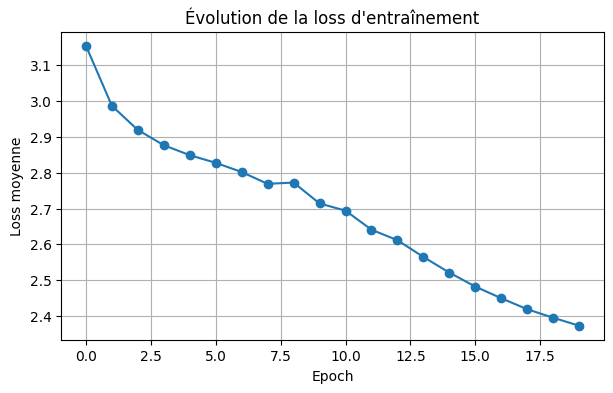

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))
plt.plot(epoch_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss moyenne")
plt.title("Évolution de la loss d'entraînement")
plt.grid(True)
plt.show()

## Question 13
Si la loss d'entraînement baisse, que peut-on conclure sur le comportement du modèle ?

# Partie 10 — Évaluer le modèle comme modèle de langage

Nous allons mesurer :
- une **accuracy token par token** ;
- un **error rate** ;
- éventuellement une matrice de confusion.

Attention : l'accuracy seule n'est pas la métrique la plus naturelle pour un modèle de langage.
La **perplexité** et la **cross-entropy** sont souvent plus pertinentes.

In [47]:
model.eval()
correct_predictions = 0
total_predictions = 0

with torch.no_grad():
    for X_test, y_test in data.get_dataloader(False):
        if torch.cuda.is_available():
            X_test = X_test.to(device)
            y_test = y_test.to(device)

        y_hat = model(X_test)
        y_hat = y_hat.reshape(-1, y_hat.shape[-1])
        y_test = y_test.reshape(-1)

        predicted_tokens = torch.argmax(y_hat, dim=1)
        correct_predictions += (predicted_tokens == y_test).sum().item()
        total_predictions += y_test.numel()

accuracy = correct_predictions / total_predictions
error_rate = 1 - accuracy

print(f"Accuracy token-level : {accuracy:.4f}")
print(f"Error rate           : {error_rate:.4f}")

Accuracy token-level : 0.3249
Error rate           : 0.6751


## Question 14
Pourquoi la perplexité est-elle souvent plus informative que l'accuracy pour juger un modèle de langage ?

# Partie 11 — Génération après apprentissage

C'est ici que le notebook montre clairement le **RNN comme modèle de langage** :
- on donne un préfixe ;
- le modèle construit un état caché cohérent ;
- il prédit le caractère suivant ;
- il réinjecte sa sortie ;
- il continue auto-régressivement.

In [48]:
print("Texte généré après apprentissage :")
print(model.predict("time ", 80, data.vocab, d2l.try_gpu()))

Texte généré après apprentissage :
time the the the the the the the the the the the the the the the the the the the the 


## Question 15
En quoi cette génération montre-t-elle que le RNN est bien utilisé comme **modèle de langage** et non comme simple classifieur statique ?

# Partie 12 — Expérience : augmenter la taille cachée

Le notebook d'origine explore aussi l'effet d'une mémoire plus grande.
Nous allons comparer un modèle avec davantage d'unités cachées.

In [50]:
new_num_hiddens = 128
new_rnn = RNNScratch(num_inputs=len(data.vocab), num_hiddens=new_num_hiddens)
new_model = RNNLMScratch(new_rnn, vocab_size=len(data.vocab), lr=0.001)
new_trainer = d2l.Trainer(max_epochs=50, gradient_clip_val=1, num_gpus=1)
new_model.trainer = new_trainer  # Attach trainer to model

if torch.cuda.is_available():
    new_model = new_model.to(device)

if not hasattr(new_trainer, "optimizer"):
    new_trainer.optimizer = new_model.configure_optimizers()

new_epoch_losses = []
num_epochs_new = 30

for epoch in range(num_epochs_new):
    new_model.train()
    total_loss = 0.0
    num_batches = 0

    for X_batch, y_batch in data.get_dataloader(True):
        if torch.cuda.is_available():
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

        new_trainer.optimizer.zero_grad()
        # Compute loss directly to avoid training_step plotting issues
        y_hat = new_model(X_batch)
        loss_new = new_model.loss(y_hat, y_batch)
        loss_new.backward()
        new_trainer.clip_gradients(new_trainer.gradient_clip_val, new_model)
        new_trainer.optimizer.step()

        total_loss += float(loss_new)
        num_batches += 1

    avg_loss_new = total_loss / max(num_batches, 1)
    new_epoch_losses.append(avg_loss_new)
    print(f"Epoch {epoch+1:02d}/{num_epochs_new} - loss moyenne : {avg_loss_new:.4f}")

Epoch 01/30 - loss moyenne : 3.3319
Epoch 02/30 - loss moyenne : 3.3315
Epoch 03/30 - loss moyenne : 3.3310
Epoch 04/30 - loss moyenne : 3.3306
Epoch 05/30 - loss moyenne : 3.3302
Epoch 06/30 - loss moyenne : 3.3298
Epoch 07/30 - loss moyenne : 3.3294
Epoch 08/30 - loss moyenne : 3.3289
Epoch 09/30 - loss moyenne : 3.3285
Epoch 10/30 - loss moyenne : 3.3281
Epoch 11/30 - loss moyenne : 3.3277
Epoch 12/30 - loss moyenne : 3.3273
Epoch 13/30 - loss moyenne : 3.3268
Epoch 14/30 - loss moyenne : 3.3264
Epoch 15/30 - loss moyenne : 3.3260
Epoch 16/30 - loss moyenne : 3.3256
Epoch 17/30 - loss moyenne : 3.3252
Epoch 18/30 - loss moyenne : 3.3247
Epoch 19/30 - loss moyenne : 3.3243
Epoch 20/30 - loss moyenne : 3.3239
Epoch 21/30 - loss moyenne : 3.3235
Epoch 22/30 - loss moyenne : 3.3231
Epoch 23/30 - loss moyenne : 3.3226
Epoch 24/30 - loss moyenne : 3.3222
Epoch 25/30 - loss moyenne : 3.3218
Epoch 26/30 - loss moyenne : 3.3214
Epoch 27/30 - loss moyenne : 3.3210
Epoch 28/30 - loss moyenne :

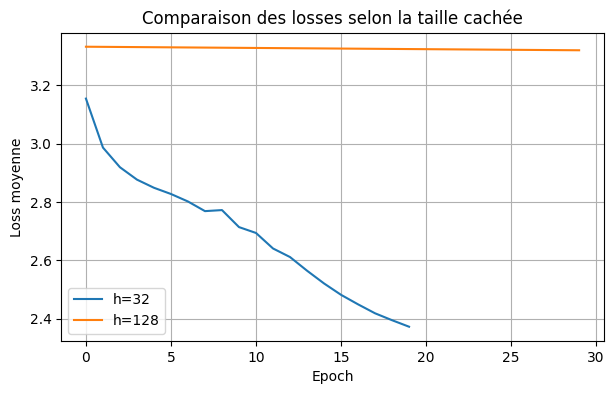

In [52]:
plt.figure(figsize=(7,4))
plt.plot(epoch_losses, label="h=32")
plt.plot(new_epoch_losses, label="h=128")
plt.xlabel("Epoch")
plt.ylabel("Loss moyenne")
plt.title("Comparaison des losses selon la taille cachée")
plt.legend()
plt.grid(True)
plt.show()

## Question 16
Que gagne-t-on potentiellement en augmentant `num_hiddens` ? Quel risque supplémentaire cela peut-il introduire ?

# Partie 13 — Bilan conceptuel

À ce stade, le TP doit avoir montré clairement que le RNN joue ici le rôle de **modèle de langage** :

1. il lit une séquence caractère par caractère ;
2. il met à jour une mémoire cachée ;
3. il produit à chaque temps une distribution sur le vocabulaire ;
4. il est entraîné à prédire le caractère suivant ;
5. il peut générer du texte auto-régressivement.

## Ce qu'il faut absolument savoir expliquer
- pourquoi le RNN a une mémoire ;
- pourquoi on utilise one-hot ;
- pourquoi la sortie est de dimension `vocab_size` ;
- pourquoi on utilise l'entropie croisée ;
- pourquoi le clipping est utile ;
- pourquoi la génération dépend du préfixe.

## Travail demandé
Rédiger une conclusion personnelle de 10 à 15 lignes répondant à la question :

> **En quoi ce notebook montre-t-il qu'un RNN peut être interprété comme un modèle de langage caractère par caractère ?**

# Partie 14 — Questions de synthèse pour le compte rendu

1. Expliquer la différence entre `RNNScratch` et `RNNLMScratch`.
2. Expliquer pourquoi `output_layer` est nécessaire.
3. Donner la forme de `one_hot(X)` si `X` a la forme `(batch_size, num_steps)`.
4. Expliquer la logique du `predict(prefix, num_preds, vocab)`.
5. Expliquer pourquoi le modèle n'apprend pas tout le passé du corpus de façon parfaite.
6. Discuter les limites d'un petit RNN simple pour les dépendances longues.
7. Proposer deux améliorations réalistes : GRU/LSTM, embeddings, dropout, température, Transformer.

## Fin du TP
Ce TP peut être prolongé par :
- une comparaison avec `nn.RNN` ;
- une version GRU ;
- une version LSTM ;
- un passage du niveau caractère au niveau mot.